# Lab Session 3 — Medical Image Registration
**Medical Image Analysis · Degree in Biomedical Engineering (URJC)**

**Authors:** Álvaro · César

Part 2: implementation of a **2D rigid registration algorithm** in Python
(transform → interpolation → metric → optimization).

## 0. Imports and paths

In [1]:
from pathlib import Path
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from scipy import optimize


def find_data_dir(start=None, folder="data"):
    """Walk up from the current directory until a folder named `data` is found.
    Works no matter where the repo is cloned or from which subfolder the notebook runs."""
    here = Path(start or Path.cwd()).resolve()
    for p in [here, *here.parents]:
        if (p / folder).is_dir():
            return p / folder
    raise FileNotFoundError(f"'{folder}' folder not found from {here}")


DATA_DIR = find_data_dir()
MR1_PATH = DATA_DIR / "mr1.nii"
MR2_PATH = DATA_DIR / "mr2.nii"
CT_PATH  = DATA_DIR / "ct.nii"

for p in (MR1_PATH, MR2_PATH, CT_PATH):
    print(f"{p.name:8s} found: {p.exists()}")

np.random.seed(0)

mr1.nii  found: True
mr2.nii  found: True
ct.nii   found: True


## 1. Load data and select a slice
Load `mr1.nii`, take a central axial slice and normalize it to [0, 1].

In [4]:
# TODO: load the volume with nib.load(...).get_fdata() and print its shape
vol = nib.load(MR1_PATH).get_fdata()
print(vol.shape)


(164, 241, 241)


In [5]:
# TODO: pick a central axial slice (3rd dimension) and normalize to [0, 1]
z = vol.shape[2] // 2      
slice_ax = vol[:, :, z]    
print(slice_ax.shape)      

(164, 241)


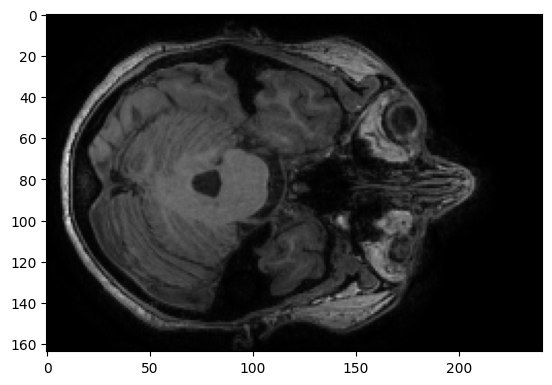

In [7]:
# TODO: display the slice (plt.imshow, cmap="gray")
plt.imshow(slice_ax, cmap="gray")


## 2. Interpolation (bilinear)  *(César)*
The statement asks for trilinear interpolation; since we work in 2D we implement **bilinear**.
Given non-integer coordinates, estimate the intensity from the 4 neighbouring pixels.

In [9]:
def bilinear_interp(img, rows, cols):
    """Sample `img` at non-integer coordinates (rows, cols) with bilinear interpolation.
    Points outside the image -> 0.
    """
    H,W = img.shape()

    #Neighbors Parts
    r0 = np.floor(rows).astype(int)
    c0 = np.floor(cols).astype(int)
    r1 = r0 + 1 
    c1 = c0 + 1

    #2. Weights 
    wr = rows - r0 
    wc = cols - c0 
    inside = (r0 >= 0) & (r1 <= H - 1) & (c0 >= 0) & (c1 <= W - 1)  #Esto indica que son los 4 bordes que debemos interopolar

    r0 = np.clip(r0, 0, H - 1); r1 = np.clip(r1, 0, H - 1)
    c0 = np.clip(c0, 0, W - 1); c1 = np.clip(c1, 0, W - 1)

    out = (img[r0, c0] * (1 - wr) * (1 - wc) +
           img[r0, c1] * (1 - wr) * wc +
           img[r1, c0] * wr * (1 - wc) +
           img[r1, c1] * wr * wc)

    out[~inside] = 0
    return out



In [ ]:
# TEST: compare against scipy.ndimage.map_coordinates(img, coords, order=1)

## 3. Rigid transform  *(César)*
Apply a rotation `theta` (degrees) and translation `tx`, `ty` (pixels) around the image centre,
using **inverse mapping** + the interpolation function above.

In [ ]:
def rigid_transform(img, theta, tx, ty):
    """Apply a 2D rigid transform (rotation about the centre + translation) to `img`."""
    # TODO 1: grid of output pixel coordinates (np.indices / np.meshgrid)
    # TODO 2: centre the coordinates
    # TODO 3: apply the INVERSE transform (remove translation, rotate by -theta)
    # TODO 4: undo the centring and interpolate with bilinear_interp
    pass

In [ ]:
# TEST: theta=0, t=0 -> identical image ; theta=90 -> compare with np.rot90

## 4. Metric: Mutual Information  *(Álvaro)*
Mutual information between two images from their joint histogram.

In [ ]:
def mutual_information(img1, img2, bins=32):
    """Mutual information between two images of the same shape."""
    # TODO 1: joint histogram with np.histogram2d
    # TODO 2: normalize -> pxy ; marginals px, py
    # TODO 3: MI = sum pxy * log(pxy / (px * py)) only where pxy > 0
    pass

In [ ]:
# TEST: MI(img, img) should be maximal ; MI decreases when one image is shifted

## 5. Optimization  *(César)*
Find `[theta, tx, ty]` that maximize MI  →  minimize `-MI` with `scipy.optimize.minimize`
(derivative-free method, e.g. Powell).

In [ ]:
def cost(params, fixed, moving):
    """-MI between the fixed image and the transformed moving image."""
    # TODO
    pass

In [ ]:
def register(fixed, moving, x0=(0.0, 0.0, 0.0)):
    """Rigid registration of `moving` onto `fixed`. Returns the estimated [theta, tx, ty]."""
    # TODO: optimize.minimize(cost, x0, args=(fixed, moving), method="Powell", callback=...)
    pass

## 6. Test: recover a known transform

In [ ]:
# TODO: true parameters (e.g. theta=10, tx=5, ty=-3) and moving image

In [ ]:
# TODO: run the registration

In [ ]:
# TODO: table true vs. estimated vs. error (careful with the sign convention!)

In [ ]:
# TODO: figure with 4 panels: fixed / moving / registered / |fixed - registered|

In [ ]:
# TODO (optional): plot MI across iterations (saved in the callback)

## 7. Discussion and conclusions
*TODO*